In [1]:
import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import scanpy as sc
import scvi
import numpy as np
import matplotlib.pyplot as plt
from lightning.pytorch import seed_everything

seed_everything(12345)

import os
import bbknn
from scipy import sparse
import matplotlib.pyplot as plt

/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  return module_get_attr_redirect(attr_n

In [2]:
adata = sc.read("./IWD_plaque.h5ad")

In [3]:
#adata = adata2[adata2.obs['domain'] == 'peri_tumor'].copy()
adata.obsm['spatial'] = adata.obsm['X_spatial']

In [4]:
sc.pp.filter_genes(adata, min_counts=3)
sc.pp.filter_cells(adata, min_counts=50)
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)
adata.obs['batch'] = 1 ### set batch to 1

In [8]:
# select the neighborhood range
sq.gr.spatial_neighbors(adata, library_key='group', coord_type='generic', delaunay=True,
                       # radius=100,
                        spatial_key='spatial', percentile=99)
cc.gr.remove_long_links(adata,distance_percentile = 95.0)



In [10]:
adata.obsm['spatial'] = adata.obsm['spatial'].astype(np.float64)# convert coordinates to float
adata.obs['batch'] = adata.obs['batch'].astype('category')
adata

AnnData object with n_obs × n_vars = 434195 × 5006
    obs: 'orig.ident', 'nCount_Xenium', 'nFeature_Xenium', 'Cell_Anno', 'group', 'Type', 'barcode', 'n_counts', 'batch', '_scvi_batch', '_scvi_labels', 'cluster_cellcharter'
    var: 'n_counts'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'spatial_neighbors'
    obsm: 'X_spatial', 'spatial', 'X_scVI', 'X_cellcharter'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [11]:
adata.obs['cluster_cellcharter']

aaaaafno-1_CWD    1
aaaahjae-1_CWD    1
aaaakdoo-1_CWD    1
aaaapapn-1_CWD    1
aaabalnp-1_CWD    1
                 ..
oijgglfa-1_IWD    3
oijgnfga-1_IWD    3
oijhncid-1_IWD    3
oijicmkl-1_IWD    3
oijijfhf-1_IWD    3
Name: cluster_cellcharter, Length: 434195, dtype: category
Categories (6, object): ['0', '1', '2', '3', '4', '5']

In [10]:
############## start from here after the neighborhood is computed
#adata.write("./adata_stroma_CN.h5ad")
#adata = sc.read("./AD_whole_brain.h5ad")

In [9]:
celltype_colors = {
    'Inf EC': '#d51f26',
    'EndMT EC': "#f3758a",
    'Angio EC': "#ff87bbff",
    'Res EC': "#fbaeb5",
    'T cell': '#0F7240',
    'B cell': '#B7B663',
    'Res Mac': '#d5a339',
    'LAMs': '#f8ff00',
    'Inf Mac': '#fccc3a',
    'vSMC': '#9d9ac6',
    'FMC_1': '#bbe379','FMC_2': '#00a7fa','FMC_3': '#b9e6fb',
    'FMC_4': '#354c85','FMC_5': '#b1ddcc','FMC_6': '#C9E1AF','FMC_7': '#31aaaa',
    
}

# ensure Celltype is a categorical variable
if not isinstance(adata.obs['Cell_Anno'].dtype, pd.CategoricalDtype):
    adata.obs['Cell_Anno'] = pd.Categorical(adata.obs['Cell_Anno'])

# store the colors into adata.uns in category order
categories = adata.obs['Cell_Anno'].cat.categories
adata.uns['Cell_Anno_colors'] = [celltype_colors[cat] for cat in categories]

adata.obs['Type'].unique()
adata.obs['condition'] = adata.obs['Type'].str.split('-').str[0].astype('category')

In [4]:
adata.obs['region']

aaaacdpa-1_IWD       Ctx
aaaafgfc-1_IWD       Ctx
aaablnao-1_IWD       Ctx
aaabncmd-1_IWD       Ctx
aaaceopa-1_IWD       Ctx
                   ...  
oijodpgg-1_CWD    Others
oijoileg-1_CWD    Others
oijojgpi-1_CWD    Others
oijopfam-1_CWD    Others
oijpdipg-1_CWD        Hy
Name: region, Length: 434195, dtype: category
Categories (6, object): ['Cp', 'Ctx', 'Hip', 'Hy', 'Others', 'Th']

In [14]:
#adata_subgroup1 = adata[adata.obs['banksy_niche'] == 'niche_3']
#adata.obs['condition'] = adata.obs['Type'].str.split('-').str[0].astype('category')
#adata_subgroup1 = adata[adata.obs['banksy_niche'].isin(['niche_1', 'niche_4', 'niche_6', 'niche_7'])].copy()
adata_subgroup1 = adata[adata.obs['Type'] == 'CWD']


/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/cellcharter/gr/_nhood.py:236: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{cluster_key}_nhood_enrichment"] = result


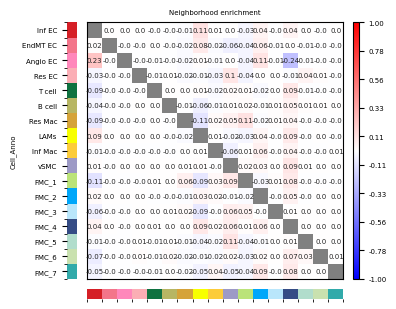

In [15]:
cc.gr.nhood_enrichment(
    adata_subgroup1,
    cluster_key='Cell_Anno',###
)

cc.pl.nhood_enrichment(
    adata_subgroup1,
    cluster_key='Cell_Anno',
    annotate=True,
    vmin=-1,
    vmax=1,
    figsize=(3,3),
    fontsize=5,
)
plt.savefig('./CWD_neiborhood.pdf', bbox_inches='tight',  dpi=500 )
####

In [15]:
adata

AnnData object with n_obs × n_vars = 12533 × 13877
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'group', 'Celltype', 'banksy_niche', 'Type', 'n_counts', 'batch', '_scvi_batch', '_scvi_labels'
    var: 'n_counts'
    uns: 'spatial', 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'spatial_neighbors', 'Celltype_colors'
    obsm: 'spatial', 'X_scVI'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [12]:
#
adata.obs['condition'] = adata.obs['Type'].str.split('-').str[0].astype('category')
cc.gr.diff_nhood_enrichment(
    adata,
    cluster_key='Cell_Anno',
    condition_key='condition',
    library_key='Type',
    pvalues=True,
    n_jobs=15,
    n_perms=100
)

  0%|          | 0/100 [00:00<?, ?it/s]

In [13]:
#
cc.pl.diff_nhood_enrichment(
    adata,
    cluster_key='Cell_Anno',
    condition_key='condition',
    condition_groups=['IWD', 'CWD'],
    annotate=True,
    figsize=(3,3),
    significance=0.05,
    fontsize=5
)
plt.savefig( './plaque_diff_enrich.pdf',  bbox_inches='tight',  dpi=500)
plt.close() ##